In [1]:
## to get requirememts for the unit-2 hf code 
! pip install -r https://raw.githubusercontent.com/huggingface/deep-rl-class/main/notebooks/unit2/requirements-unit2.txt

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'pyyaml' when getting requirements to build wheel


In [2]:
!pip install gymnasium pygame numpy huggingface_hub pyyaml>=6.0.1

In [3]:
! pip install pickle5

  Using cached pickle5-0.0.11.tar.gz (132 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for pickle5 (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for pickle5
Failed to build pickle5
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> pickle5


In [4]:
%%bash                               
# install specific modules and lib
apt-get install -y python3-opengl ffmpeg xvfb
pip install pyvirtualdisplay

Reading package lists...
Building dependency tree...
Reading state information...
ffmpeg is already the newest version (7:6.1.1-3ubuntu5).
xvfb is already the newest version (2:21.1.12-1ubuntu1.9).
The following additional packages will be installed:
  libegl-dev libgl-dev libgl1-mesa-dev libgles-dev libgles1 libglu1-mesa
  libglu1-mesa-dev libglut-dev libglut3.12 libglvnd-core-dev libglvnd-dev
  libglx-dev libopengl-dev
Suggested packages:
  libgle3 python3-tk
The following NEW packages will be installed:
  libegl-dev libgl-dev libgl1-mesa-dev libgles-dev libgles1 libglu1-mesa
  libglu1-mesa-dev libglut-dev libglut3.12 libglvnd-core-dev libglvnd-dev
  libglx-dev libopengl-dev python3-opengl
0 upgraded, 14 newly installed, 0 to remove and 54 not upgraded.
Need to get 1,463 kB of archives.
After this operation, 12.4 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 libglx-dev amd64 1.7.0-1build1 [14.2 kB]
Get:2 http://archive.ubuntu.com/ub

In [ ]:
# restarting termical 
## (note) :  use only after downloading module 
import os

os.kill(os.getpid(), 9)

## From here actual code starts !

In [1]:
# Virtual display
from pyvirtualdisplay import Display

virtual_display = Display(visible=0, size=(1400, 900))
virtual_display.start()

In [2]:
## lets import packages 
import numpy as np
import gymnasium as gym
import random  # this for epsilon greedy 
import imageio # this for replay video
import os
import tqdm
import pickle # here actually the pickle5 in original code but its wheels are not sutiable for this env as the python here is 3.224 and pickle5 supports only till 3.8
from tqdm.notebook import tqdm

In [3]:
## building environment 
env = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False, render_mode="rgb_array")
## here , map_name = 4x4 and grid 
## is_slippery =False the determinstic state
## render_mode = for recoring video 

In [4]:
## let's see what environment looks 
print("_____OBSERVATION SPACE_____ \n")
print("Observation Space :", env.observation_space) # this 16 are the steps/position in block 
# current position as current_row * ncols + current_col 
print("Sample observation :", env.observation_space.sample())  # Get a random observation

_____OBSERVATION SPACE_____ 

Observation Space : Discrete(16)
Sample observation : 13


In [5]:
## what's in action space 
print("\n _____ACTION SPACE_____ \n")
print("Action Space Shape :", env.action_space.n) # (1:"go left",2:"go right",3:"go up".4:"go down")
print("Action Space Sample :", env.action_space.sample())  # Take a random action


 _____ACTION SPACE_____ 

Action Space Shape : 4
Action Space Sample : 2


### Lets initialize the Q-Table
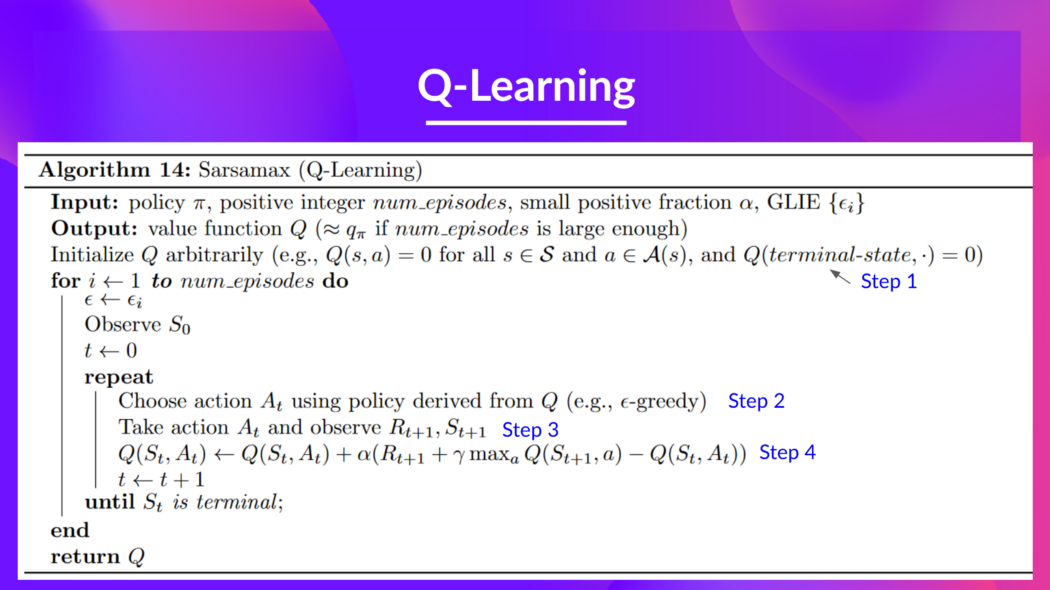
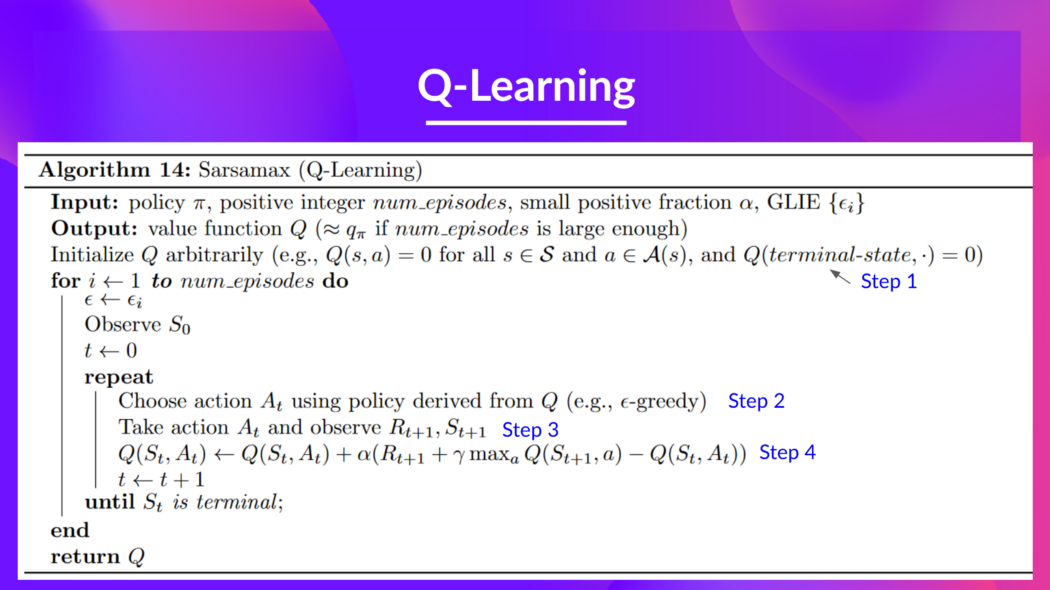

In [6]:
# Let's create our Qtable of size (state_space, action_space) and initialized each values at 0 using np.zeros. np.zeros needs a tuple (a,b)
def initialize_q_table(state_space, action_space):
  Qtable = np.zeros((state_space, action_space)) # the initial decelaration -> all vlaues are set to zero
  return Qtable

In [7]:
state_space = env.observation_space.n
print("There are ", state_space, " possible states")

action_space = env.action_space.n
print("There are ", action_space, " possible actions")

There are  16  possible states
There are  4  possible actions


In [8]:
Qtable_frozenlake = initialize_q_table(state_space, action_space)

In [9]:
## defining: Greedy Policy 
## since the q learning is off-policy algorithm - thier are two policy one for updating (greedy) and one for acting (epsilon-greedy)
def greedy_policy(Qtable, state):
    # Exploitation: take the action with the highest state, action value
    action = np.argmax(Qtable[state][:]) # for any given position take its whole learned q table to decide and optiomal policy for next step
    return action

# prob = 1 - e -> we do exploitation (i.e or agent select the action with highes state action pair value)
# prob = e -> we do exploraition (trying random action)

# as are training continuous, we reduce epsilon value as we required less exploration and more exploitation 

In [10]:
# define epsilon-greedy-policy
def epsilon_greedy_policy(Qtable,state,epsilon):
    random_num = random.uniform(0,1) # and random number between 0,1 as prob
    if random_num > epsilon:
        action = greedy_policy(Qtable,state)
        # exploitation
    else:
        #exploration 
        action = env.action_space.sample() # taking random 
    return action 

In [11]:
## define hyperparameters 
## The exploration related hyperparamters are some of the most important ones.
# 1. We need to make sure that our agent explores enough of the state space to learn a good value approximation. To do that, we need to have progressive decay of the epsilon.
# 2. If you decrease epsilon too fast (too high decay_rate), you take the risk that your agent will be stuck, since your agent didn’t explore enough of the state space and hence can’t solve the problem.

# Training parameters
n_training_episodes = 10000  # Total training episodes
learning_rate = 0.7  # Learning rate

# Evaluation parameters
n_eval_episodes = 100  # Total number of test episodes

# Environment parameters
env_id = "FrozenLake-v1"  # Name of the environment
max_steps = 99  # Max steps per episode
gamma = 0.95  # Discounting rate
eval_seed = []  # The evaluation seed of the environment

# Exploration parameters
max_epsilon = 1.0  # Exploration probability at start
min_epsilon = 0.05  # Minimum exploration probability
decay_rate = 0.0005  # Exponential decay rate for exploration prob

In [12]:
## creating training loop/method
# For episode in the total of training episodes:

# Reduce epsilon (since we need less and less exploration)
# Reset the environment

#   For step in max timesteps:
#     Choose the action At using epsilon greedy policy
#     Take the action (a) and observe the outcome state(s') and reward (r)
#     Update the Q-value Q(s,a) using Bellman equation Q(s,a) + lr [R(s,a) + gamma * max Q(s',a') - Q(s,a)]
#     If done, finish the episode
#     Our next state is the new state

In [13]:
def train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env, max_steps, Qtable):
    for episode in tqdm(range(n_training_episodes)):
        # redusing epsilon 
        epsilon = min_epsilon + (max_epsilon - min_epsilon)*np.exp(-decay_rate*episode)
        # reset the env -> new eposide
        state, info = env.reset()
        step = 0
        terminated = False
        truncated = False

        # repeat 
        for step in range(max_steps):
            action = epsilon_greedy_policy(Qtable,state,epsilon) # Choose the action At using epsilon greedy policy
            # Take action At and observe Rt+1 and St+1
            # Take the action (a) and observe the outcome state(s') and reward (r)
            new_state,reward,terminated,truncated,info = env.step(action)
            # Update Q(s,a):= Q(s,a) + lr [R(s,a) + gamma * max Q(s',a') - Q(s,a)]
            Qtable[state][action] = Qtable[state][action] + learning_rate * (
                reward + gamma * np.max(Qtable[new_state]) - Qtable[state][action]
            )

            # finish the eposide 
            if terminated or truncated:
                break

            # our next state is the new state
            state = new_state
    return Qtable

In [14]:
## train Qlearning agent 
Qtable_frozenlake = train(n_training_episodes, min_epsilon, max_epsilon, decay_rate, env, max_steps, Qtable_frozenlake)

  0%|          | 0/10000 [00:00<?, ?it/s]

In [15]:
Qtable_frozenlake

array([[0.73509189, 0.77378094, 0.77378094, 0.73509189],
       [0.73509189, 0.        , 0.81450625, 0.77378094],
       [0.77378094, 0.857375  , 0.77378094, 0.81450625],
       [0.81450625, 0.        , 0.77378086, 0.77377947],
       [0.77378094, 0.81450625, 0.        , 0.73509189],
       [0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.9025    , 0.        , 0.81450625],
       [0.        , 0.        , 0.        , 0.        ],
       [0.81450625, 0.        , 0.857375  , 0.77378094],
       [0.81450625, 0.9025    , 0.9025    , 0.        ],
       [0.857375  , 0.95      , 0.        , 0.857375  ],
       [0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        ],
       [0.        , 0.9025    , 0.95      , 0.857375  ],
       [0.9025    , 0.95      , 1.        , 0.9025    ],
       [0.        , 0.        , 0.        , 0.        ]])

In [16]:
Qtable_frozenlake.shape # our qtable for 4x4 with 16 positions 

(16, 4)

In [17]:
## the evaluation mention 
def evaluate_agent(env, max_steps, n_eval_episodes, Q, seed):
    """
    Evaluate the agent for ``n_eval_episodes`` episodes and returns average reward and std of reward.
    :param env: The evaluation environment
    :param n_eval_episodes: Number of episode to evaluate the agent
    :param Q: The Q-table
    :param seed: The evaluation seed array (for taxi-v3)
    """
    episode_rewards = []
    for episode in tqdm(range(n_eval_episodes)):
        if seed:
            state, info = env.reset(seed=seed[episode])
        else:
            state, info = env.reset()
        step = 0
        truncated = False
        terminated = False
        total_rewards_ep = 0

        for step in range(max_steps):
            # Take the action (index) that have the maximum expected future reward given that state
            action = greedy_policy(Q, state)
            new_state, reward, terminated, truncated, info = env.step(action)
            total_rewards_ep += reward

            if terminated or truncated:
                break
            state = new_state
        episode_rewards.append(total_rewards_ep)
    mean_reward = np.mean(episode_rewards)
    std_reward = np.std(episode_rewards)

    return mean_reward, std_reward

In [18]:
#3 usually u should have mean reward of 1.0
# Evaluate our Agent
mean_reward, std_reward = evaluate_agent(env, max_steps, n_eval_episodes, Qtable_frozenlake, eval_seed)
print(f"Mean_reward={mean_reward:.2f} +/- {std_reward:.2f}")

  0%|          | 0/100 [00:00<?, ?it/s]

Mean_reward=1.00 +/- 0.00


In [19]:
## publish to hub 
from huggingface_hub import HfApi, snapshot_download
from huggingface_hub.repocard import metadata_eval_result, metadata_save

from pathlib import Path
import datetime
import json

In [20]:
def record_video(env, Qtable, out_directory, fps=1):
    """
    Generate a replay video of the agent
    :param env
    :param Qtable: Qtable of our agent
    :param out_directory
    :param fps: how many frame per seconds (with taxi-v3 and frozenlake-v1 we use 1)
    """
    images = []
    terminated = False
    truncated = False
    state, info = env.reset(seed=random.randint(0, 500))
    img = env.render()
    images.append(img)
    while not terminated or truncated:
        # Take the action (index) that have the maximum expected future reward given that state
        action = np.argmax(Qtable[state][:])
        state, reward, terminated, truncated, info = env.step(
            action
        )  # We directly put next_state = state for recording logic
        img = env.render()
        images.append(img)
    imageio.mimsave(out_directory, [np.array(img) for i, img in enumerate(images)], fps=fps)

In [21]:
def push_to_hub(repo_id, model, env, video_fps=1, local_repo_path="hub"):
    """
    Evaluate, Generate a video and Upload a model to Hugging Face Hub.
    This method does the complete pipeline:
    - It evaluates the model
    - It generates the model card
    - It generates a replay video of the agent
    - It pushes everything to the Hub

    :param repo_id: repo_id: id of the model repository from the Hugging Face Hub
    :param env
    :param video_fps: how many frame per seconds to record our video replay
    (with taxi-v3 and frozenlake-v1 we use 1)
    :param local_repo_path: where the local repository is
    """
    _, repo_name = repo_id.split("/")

    eval_env = env
    api = HfApi()

    # Step 1: Create the repo
    repo_url = api.create_repo(
        repo_id=repo_id,
        exist_ok=True,
    )

    # Step 2: Download files
    repo_local_path = Path(snapshot_download(repo_id=repo_id))

    # Step 3: Save the model
    if env.spec.kwargs.get("map_name"):
        model["map_name"] = env.spec.kwargs.get("map_name")
        if env.spec.kwargs.get("is_slippery", "") == False:
            model["slippery"] = False

    # Pickle the model
    with open((repo_local_path) / "q-learning.pkl", "wb") as f:
        pickle.dump(model, f)

    # Step 4: Evaluate the model and build JSON with evaluation metrics
    mean_reward, std_reward = evaluate_agent(
        eval_env, model["max_steps"], model["n_eval_episodes"], model["qtable"], model["eval_seed"]
    )

    evaluate_data = {
        "env_id": model["env_id"],
        "mean_reward": mean_reward,
        "n_eval_episodes": model["n_eval_episodes"],
        "eval_datetime": datetime.datetime.now().isoformat(),
    }

    # Write a JSON file called "results.json" that will contain the
    # evaluation results
    with open(repo_local_path / "results.json", "w") as outfile:
        json.dump(evaluate_data, outfile)

    # Step 5: Create the model card
    env_name = model["env_id"]
    if env.spec.kwargs.get("map_name"):
        env_name += "-" + env.spec.kwargs.get("map_name")

    if env.spec.kwargs.get("is_slippery", "") == False:
        env_name += "-" + "no_slippery"

    metadata = {}
    metadata["tags"] = [env_name, "q-learning", "reinforcement-learning", "custom-implementation"]

    # Add metrics
    eval = metadata_eval_result(
        model_pretty_name=repo_name,
        task_pretty_name="reinforcement-learning",
        task_id="reinforcement-learning",
        metrics_pretty_name="mean_reward",
        metrics_id="mean_reward",
        metrics_value=f"{mean_reward:.2f} +/- {std_reward:.2f}",
        dataset_pretty_name=env_name,
        dataset_id=env_name,
    )

    # Merges both dictionaries
    metadata = {**metadata, **eval}

    model_card = f"""
  # **Q-Learning** Agent playing1 **{env_id}**
  This is a trained model of a **Q-Learning** agent playing **{env_id}** .

  ## Usage

  model = load_from_hub(repo_id="{repo_id}", filename="q-learning.pkl")

  # Don't forget to check if you need to add additional attributes (is_slippery=False etc)
  env = gym.make(model["env_id"])
  """

    evaluate_agent(env, model["max_steps"], model["n_eval_episodes"], model["qtable"], model["eval_seed"])

    readme_path = repo_local_path / "README.md"
    readme = ""
    print(readme_path.exists())
    if readme_path.exists():
        with readme_path.open("r", encoding="utf8") as f:
            readme = f.read()
    else:
        readme = model_card

    with readme_path.open("w", encoding="utf-8") as f:
        f.write(readme)

    # Save our metrics to Readme metadata
    metadata_save(readme_path, metadata)

    # Step 6: Record a video
    video_path = repo_local_path / "replay.mp4"
    record_video(env, model["qtable"], video_path, video_fps)

    # Step 7. Push everything to the Hub
    api.upload_folder(
        repo_id=repo_id,
        folder_path=repo_local_path,
        path_in_repo=".",
    )

    print("Your model is pushed to the Hub. You can view your model here: ", repo_url)

In [ ]:
from huggingface_hub import notebook_login

# notebook_login()

In [23]:
# creating model dictonary 
model = {
    "env_id": env_id,
    "max_steps": max_steps,
    "n_training_episodes": n_training_episodes,
    "n_eval_episodes": n_eval_episodes,
    "eval_seed": eval_seed,
    "learning_rate": learning_rate,
    "gamma": gamma,
    "max_epsilon": max_epsilon,
    "min_epsilon": min_epsilon,
    "decay_rate": decay_rate,
    "qtable": Qtable_frozenlake,
}
model

{'env_id': 'FrozenLake-v1',
 'max_steps': 99,
 'n_training_episodes': 10000,
 'n_eval_episodes': 100,
 'eval_seed': [],
 'learning_rate': 0.7,
 'gamma': 0.95,
 'max_epsilon': 1.0,
 'min_epsilon': 0.05,
 'decay_rate': 0.0005,
 'qtable': array([[0.73509189, 0.77378094, 0.77378094, 0.73509189],
        [0.73509189, 0.        , 0.81450625, 0.77378094],
        [0.77378094, 0.857375  , 0.77378094, 0.81450625],
        [0.81450625, 0.        , 0.77378086, 0.77377947],
        [0.77378094, 0.81450625, 0.        , 0.73509189],
        [0.        , 0.        , 0.        , 0.        ],
        [0.        , 0.9025    , 0.        , 0.81450625],
        [0.        , 0.        , 0.        , 0.        ],
        [0.81450625, 0.        , 0.857375  , 0.77378094],
        [0.81450625, 0.9025    , 0.9025    , 0.        ],
        [0.857375  , 0.95      , 0.        , 0.857375  ],
        [0.        , 0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        , 0.        ],
        [0.

In [25]:
username = "RahulKate-173"  # FILL THIS
repo_name = "q-FrozenLake-v1-4x4-noSlippery"
push_to_hub(repo_id=f"{username}/{repo_name}", model=model, env=env)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

False


/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
ALSA lib confmisc.c:855:(parse_card) cannot find card '0'
ALSA lib conf.c:5208:(_snd_config_evaluate) function snd_func_card_inum returned error: No such file or directory
ALSA lib confmisc.c:422:(snd_func_concat) error evaluating strings
ALSA lib conf.c:5208:(_snd_config_evaluate) function snd_func_concat returned error: No such file or directory
ALSA lib confmisc.c:1342:(snd_func_refer) error evaluating name
ALSA lib conf.c:5208:(_snd_config_evaluate) function snd_func_refer returned error: No such file or directory
ALSA lib conf.c:5731:(snd_config_expand) Evaluate error: No such file or directory
ALSA lib pcm.c:2721:(snd_pcm

Your model is pushed to the Hub. You can view your model here:  https://huggingface.co/RahulKate-173/q-FrozenLake-v1-4x4-noSlippery
